# 02 - Exploratory Data Analysis

Before building any model we want to understand:
1. How the yield curve moved between 2010 and 2026, and which periods were unusual
2. What shapes the curve takes (normal, flat, inverted)
3. How the features relate to each other and to the targets
4. Whether we should predict the yield **level** or the yield **change**. This decides how the models are set up.

In [1]:
import sys
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from statsmodels.tsa.stattools import adfuller, acf

from src import config, features, plots

plots.setup()
pd.set_option("display.width", 140)

df = features.load_dataset()
print(df.shape)
df[features.ALL_FEATURES].describe().T.round(2)

(4189, 31)


,count,mean,std,min,25%,50%,75%,max
DGS1MO,4189.0,1.49,1.90,0.00,0.05,0.23,2.44,6.02
DGS3MO,4189.0,1.54,1.90,0.00,0.06,0.30,2.49,5.63
DGS1,4189.0,1.63,1.77,0.04,0.17,0.60,3.11,5.49
DGS2,4189.0,1.73,1.59,0.09,0.38,0.91,3.14,5.19
DGS5,4189.0,2.15,1.25,0.19,1.23,1.75,3.07,5.09
DGS7,4189.0,2.44,1.13,0.36,1.55,2.17,3.28,5.19
DGS10,4189.0,2.69,1.05,0.52,1.89,2.53,3.55,5.29
DGS30,4189.0,3.32,0.96,0.99,2.73,3.12,4.14,5.64
GOV_PCT,4189.0,12.95,3.24,6.08,11.17,12.42,13.93,20.26
HOM_PCT,4189.0,73.77,4.55,63.43,71.30,72.52,78.35,80.52


## 1. The yield curve from 2010 to 2026

The shaded bands mark the main interest-rate periods.

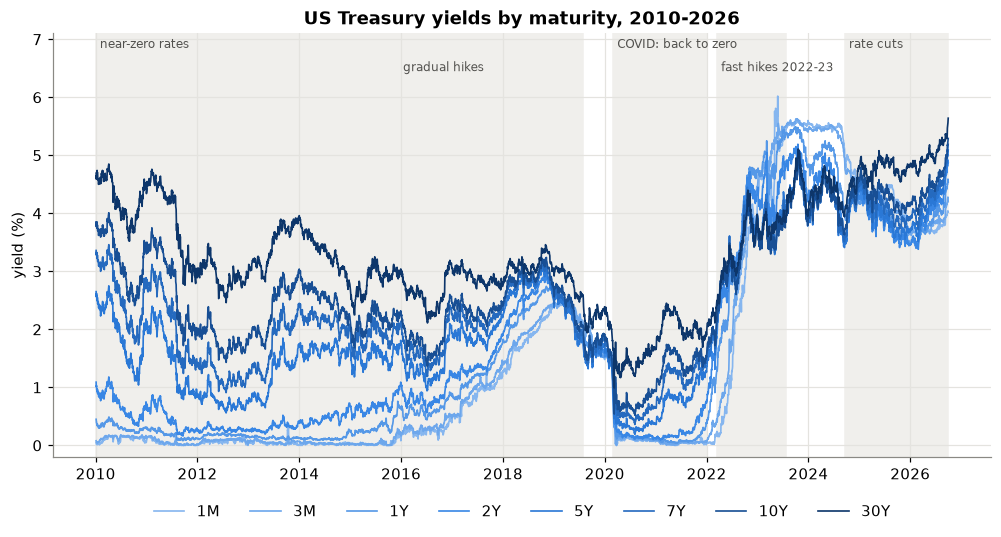

In [2]:
periods = [("2010-01-01", "2015-12-15", "near-zero rates"),
           ("2015-12-16", "2019-07-31", "gradual hikes"),
           ("2020-03-01", "2021-12-31", "COVID: back to zero"),
           ("2022-03-16", "2023-07-26", "fast hikes 2022-23"),
           ("2024-09-18", "2026-09-30", "rate cuts")]

fig, ax = plt.subplots(figsize=(11, 5))
for t in config.TENORS:
    ax.plot(df.index, df[t], color=plots.TENOR_COLORS[t], linewidth=1.1, label=config.TENOR_LABELS[t])
for i, (start, end, label) in enumerate(periods):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#f0efec", zorder=0)
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=30), 6.85 if i % 2 == 0 else 6.45, label,
            fontsize=8, color="#52514e")
ax.set_ylim(-0.2, 7.1)
ax.set_ylabel("yield (%)")
ax.set_title("US Treasury yields by maturity, 2010-2026")
ax.legend(ncol=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plots.save(fig, "02_yield_history")
plt.show()

**Observations**
- **2010-2015:** the Fed kept its rate at zero after the 2008 crisis, so the 1M and 3M yields sat at about 0% for six years. Long-term yields still moved, so the gap between short and long maturities was large.
- **2016-2019:** gradual rate hikes lifted the short end, and by 2019 all maturities were bunched together (a flat curve).
- **2020:** COVID sent every yield down. The 10Y reached its lowest point of the period, 0.52%, in August 2020.
- **2022-2023:** the fastest hikes in decades took the 1M yield from about 0% to above 5% in roughly 18 months. Short yields went above long yields, so the curve became inverted.
- **May 2023:** the 1M yield jumped to 6.02% during the debt-ceiling standoff. Investors avoided bills that matured close to a possible default date.
- **2024-2026:** rate cuts brought the 1M yield down to about 4%, but long yields kept rising. The 30Y reached 5.64% in September 2026, the highest value in the dataset.
- **Most important for modelling:** the 2023-2026 period looks very different from 2010-2021.

## 2. The whole curve as a surface

Each point is one maturity on one date. A static 3D view is shown here. An interactive version (rotate and zoom) is saved as `results/figures/02_yield_surface.html`.

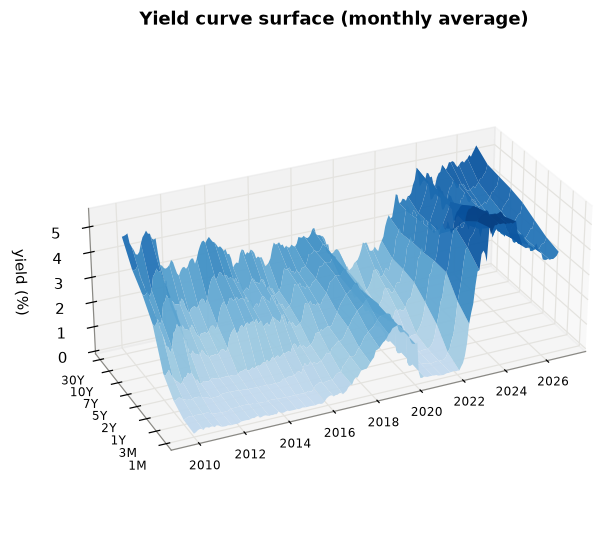

In [3]:
maturity_years = [1/12, 0.25, 1, 2, 5, 7, 10, 30]
monthly = df[config.TENORS].resample("ME").mean()

fig = plt.figure(figsize=(11, 6))
ax = fig.add_subplot(projection="3d")
X, Y = np.meshgrid(np.arange(len(monthly)), np.arange(len(config.TENORS)))
ax.plot_surface(X, Y, monthly.values.T, cmap="Blues", edgecolor="none", alpha=0.95,
                vmin=-2, vmax=6)
year_cols = [i for i, d in enumerate(monthly.index) if d.month == 1 and d.year % 2 == 0]
ax.set_xticks(year_cols)
ax.set_xticklabels([monthly.index[i].year for i in year_cols], fontsize=8)
ax.set_yticks(range(len(config.TENORS)))
ax.set_yticklabels([config.TENOR_LABELS[t] for t in config.TENORS], fontsize=8)
ax.set_zlabel("yield (%)")
ax.set_box_aspect((2.2, 1, 0.8))
ax.view_init(elev=28, azim=-115)
ax.set_title("Yield curve surface (monthly average)")
plots.save(fig, "02_yield_surface")
plt.show()

surface = go.Figure(go.Surface(x=[config.TENOR_LABELS[t] for t in config.TENORS], y=monthly.index,
                               z=monthly.values, colorscale="Blues"))
surface.update_layout(title="US Treasury yield curve 2010-2026",
                      scene=dict(xaxis_title="maturity", yaxis_title="date", zaxis_title="yield (%)"))
surface.write_html(config.FIG_DIR / "02_yield_surface.html")

## 3. Shapes of the curve

Usually long-term bonds pay more than short-term ones (an **upward sloping** or normal curve). When short-term yields are above long-term ones, the curve is **inverted**, which has often come before a recession.

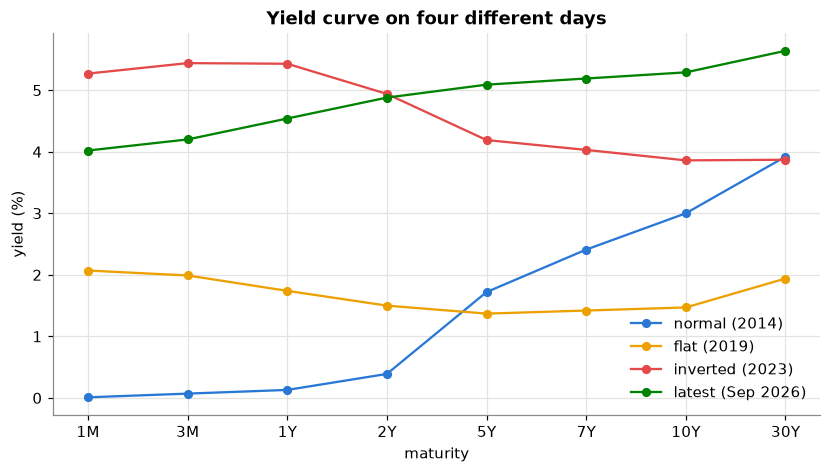

In [4]:
snapshots = {"2014-01-02": "normal (2014)", "2019-08-28": "flat (2019)",
             "2023-07-03": "inverted (2023)", "2026-09-30": "latest (Sep 2026)"}
snap_colors = [plots.BLUE, plots.YELLOW, plots.RED, plots.GREEN]

fig, ax = plt.subplots(figsize=(9, 4.5))
for (date, label), color in zip(snapshots.items(), snap_colors):
    row = df.loc[date, config.TENORS]
    ax.plot(range(len(config.TENORS)), row.values, marker="o", markersize=5, color=color, label=label)
ax.set_xticks(range(len(config.TENORS)))
ax.set_xticklabels([config.TENOR_LABELS[t] for t in config.TENORS])
ax.set_xlabel("maturity")
ax.set_ylabel("yield (%)")
ax.set_title("Yield curve on four different days")
ax.legend()
plots.save(fig, "02_curve_shapes")
plt.show()

## 4. Slope of the curve and inversions

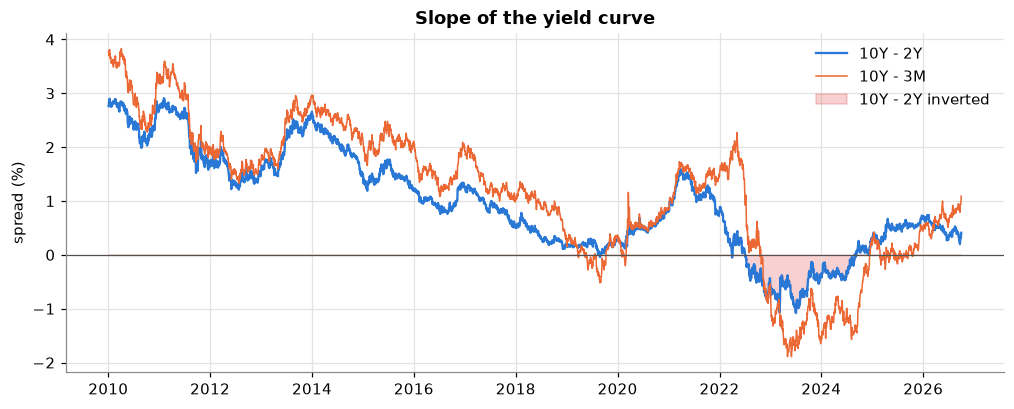

10Y-2Y inverted from 2022-07-06 to 2024-08-26 (537 trading days, deepest -1.08%)


In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df["SLOPE_10Y_2Y"], color=plots.BLUE, label="10Y - 2Y")
ax.plot(df.index, df["SLOPE_10Y_3M"], color=plots.ORANGE, linewidth=1, label="10Y - 3M")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.fill_between(df.index, df["SLOPE_10Y_2Y"].clip(upper=0), 0, color=plots.RED, alpha=0.25,
                label="10Y - 2Y inverted")
ax.set_ylabel("spread (%)")
ax.set_title("Slope of the yield curve")
ax.legend(loc="upper right")
plots.save(fig, "02_curve_slope")
plt.show()

inverted = df["SLOPE_10Y_2Y"] < 0
blocks = (inverted != inverted.shift()).cumsum()
for _, block in df[inverted].groupby(blocks[inverted]):
    if len(block) > 20:
        print(f"10Y-2Y inverted from {block.index[0].date()} to {block.index[-1].date()} "
              f"({len(block)} trading days, deepest {block['SLOPE_10Y_2Y'].min():.2f}%)")

**Observations**
- The 10Y-2Y spread was negative (inverted) from **6 July 2022 to 26 August 2024**: 537 trading days, as deep as -1.08%. This is by far the longest inversion in the data. The 10Y-3M spread inverted even more, to about -1.9%.
- There was also a short inversion of the 10Y-3M spread in mid 2019.
- Historically, an inverted curve has often come before a recession (Estrella & Mishkin, 1998), which is why investors watch the slope closely.
- By 2026 both spreads are positive again. Short rates fell with the rate cuts while long rates went up ("bear steepening").
- The slope changes slowly over months, so it describes the current regime rather than predicting next week's move.

## 5. Principal Component Analysis of the curve

The 8 maturities move together a lot. PCA on the **daily changes** of the 8 yields shows how many independent "movements" there really are.

Variance explained: {'PC1': 73.6, 'PC2': 10.4, 'PC3': 9.1, 'PC4': 3.4}
First 3 together: 93.2 %


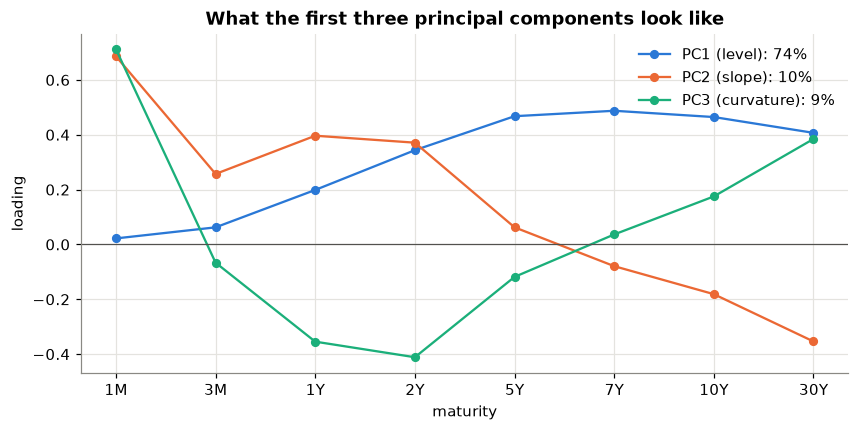

In [6]:
daily_changes = df[config.TENORS].diff().dropna()
pca = PCA(n_components=4).fit(daily_changes)
explained = pd.Series(pca.explained_variance_ratio_, index=["PC1", "PC2", "PC3", "PC4"])
print("Variance explained:", (explained * 100).round(1).to_dict())
print("First 3 together:", round(explained[:3].sum() * 100, 1), "%")

fig, ax = plt.subplots(figsize=(9, 4))
names = ["PC1 (level)", "PC2 (slope)", "PC3 (curvature)"]
for i, (name, color) in enumerate(zip(names, [plots.BLUE, plots.ORANGE, plots.AQUA])):
    loading = pca.components_[i]
    if loading.sum() < 0:          # the sign of a component is arbitrary, so flip for readability
        loading = -loading
    ax.plot(range(len(config.TENORS)), loading, marker="o", markersize=5, color=color,
            label=f"{name}: {explained.iloc[i]*100:.0f}%")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(len(config.TENORS)))
ax.set_xticklabels([config.TENOR_LABELS[t] for t in config.TENORS])
ax.set_xlabel("maturity")
ax.set_ylabel("loading")
ax.set_title("What the first three principal components look like")
ax.legend()
plots.save(fig, "02_pca_loadings")
plt.show()

**Observations**
- The first three components explain **93.2%** of all daily movements of the 8 yields:
  - PC1 = 73.6% (**level**: maturities from 1Y to 30Y move up or down together)
  - PC2 = 10.4% (**slope**: short and long end move in opposite directions)
  - PC3 = 9.1% (**curvature**: the middle moves against the two ends)
- This matches the classic finding that a few factors drive the whole curve (Litterman & Scheinkman, 1991).
- Our share is a bit lower than the usual ~99%. The 1M bill has a lot of movement of its own (debt-ceiling episodes, month-end effects), which is why its loading is close to 0 in PC1 and very large in PC2 and PC3.
- For the models, the 8 yield features carry mostly the same information. The slope and curvature features describe the shape more directly.

## 6. Correlation between features

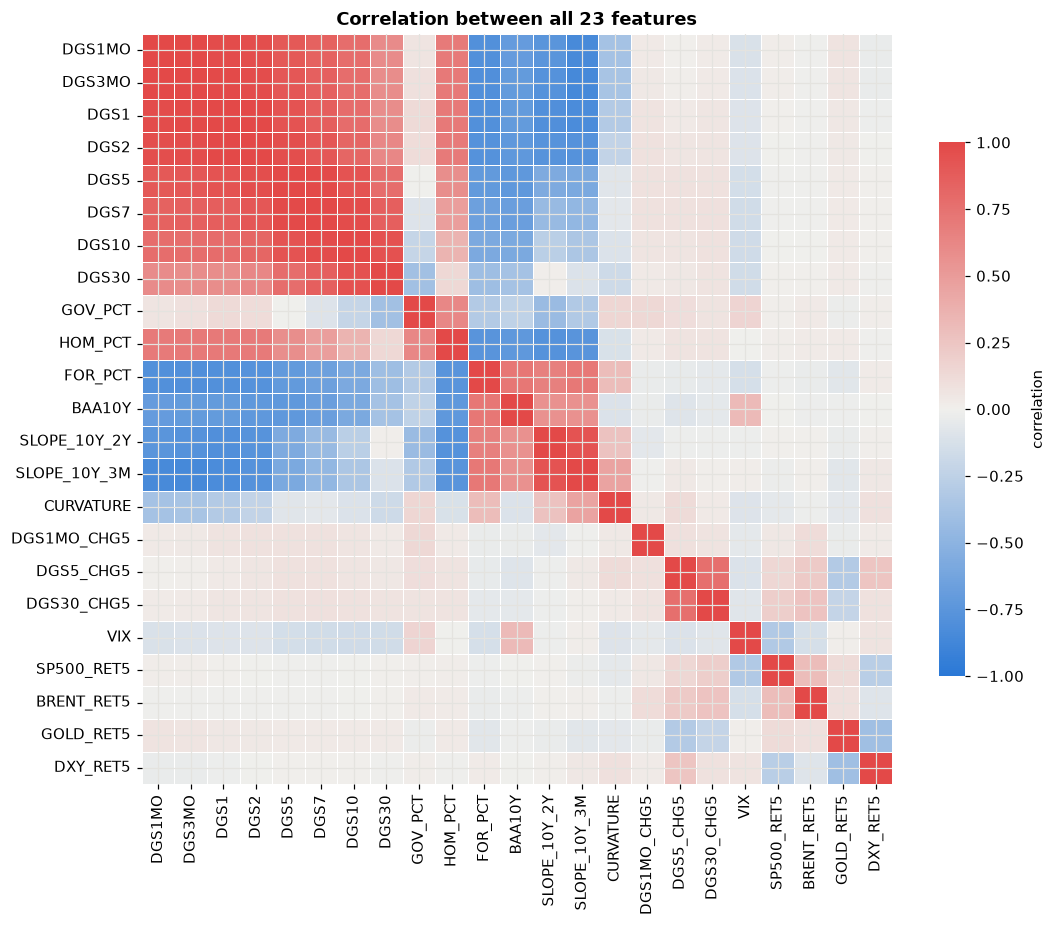

In [7]:
corr = df[features.ALL_FEATURES].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=plots.DIVERGING, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7, "label": "correlation"}, ax=ax)
ax.set_title("Correlation between all 23 features")
plots.save(fig, "02_correlation")
plt.show()

**Observations**
- The 8 yields are highly correlated with each other (red block), especially neighbouring maturities.
- The debt shares are correlated with yield levels because both trend over time. The foreign share fell while rates rose, so its correlation with the yields is negative (blue).
- The engineered 5-day changes and the market returns are hardly correlated with the yield levels, so they add new information.
- The high correlation between the inputs (multicollinearity) is not a problem for trees or neural nets. It does make linear regression coefficients unstable, so they shouldn't be read too literally.

## 7. Debt holdings, credit spread and VIX

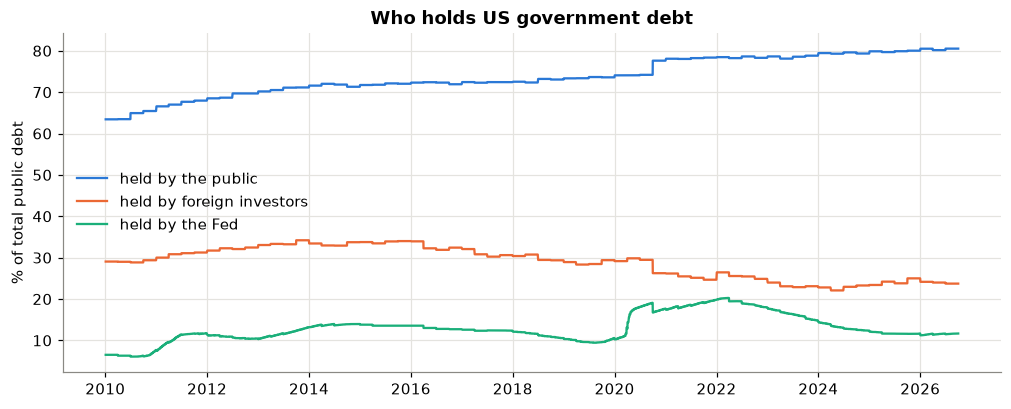

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
labels = {"HOM_PCT": "held by the public", "FOR_PCT": "held by foreign investors", "GOV_PCT": "held by the Fed"}
for col, color in zip(labels, [plots.BLUE, plots.ORANGE, plots.AQUA]):
    ax.plot(df.index, df[col], color=color, label=labels[col])
ax.set_ylabel("% of total public debt")
ax.set_title("Who holds US government debt")
ax.legend(loc="center left")
plots.save(fig, "02_debt_holdings")
plt.show()

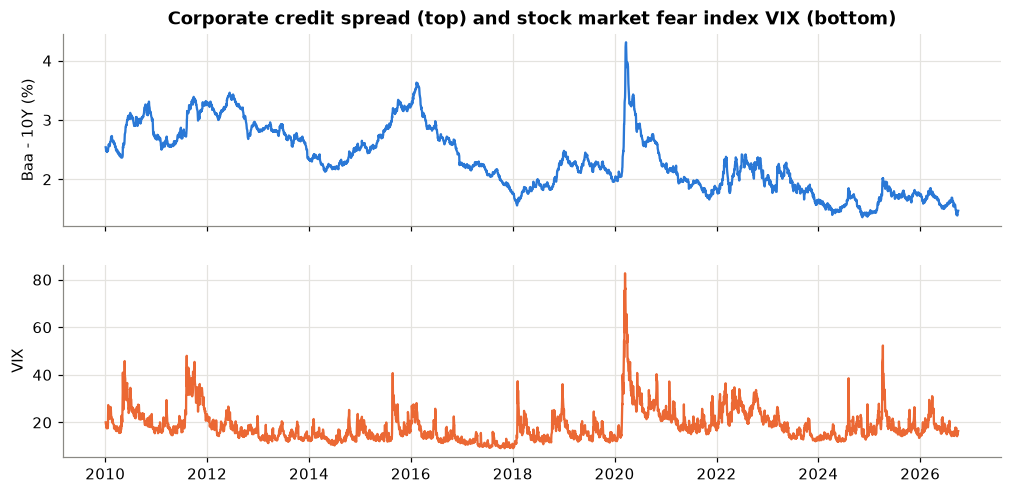

In [9]:
# two panels instead of two y-axes because the two series have different units
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(df.index, df["BAA10Y"], color=plots.BLUE)
axes[0].set_ylabel("Baa - 10Y (%)")
axes[0].set_title("Corporate credit spread (top) and stock market fear index VIX (bottom)")
axes[1].plot(df.index, df["VIX"], color=plots.ORANGE)
axes[1].set_ylabel("VIX")
plots.save(fig, "02_spread_vix")
plt.show()

**Observations**
- The share of debt held by the public rose from about 63% to about 80%, so more of the debt is now sold to markets.
- The foreign share peaked at about 34% around 2014 and has since fallen to about 23%. Foreign investors bought less of the new debt.
- The Fed's share jumped during COVID quantitative easing (QE) in 2020, peaked at about 20% in 2022, then fell as the Fed shrank its balance sheet (quantitative tightening).
- The step pattern comes from quarterly data being carried forward until the next release.
- The credit spread and VIX spike together in stress periods: 2011 (euro crisis), early 2016 (oil crash) and especially March 2020 (VIX 82.7, spread 4.31%). Both measure how scared markets are.

## 8. How much do the targets move in a week?

     std (bp)  mean abs (bp)  share of weeks with no change  skew  kurtosis
1M       9.08           3.93                           0.19  2.12     56.88
5Y      11.52           8.51                           0.05 -0.09      2.23
30Y     10.97           8.39                           0.04 -0.13      1.41


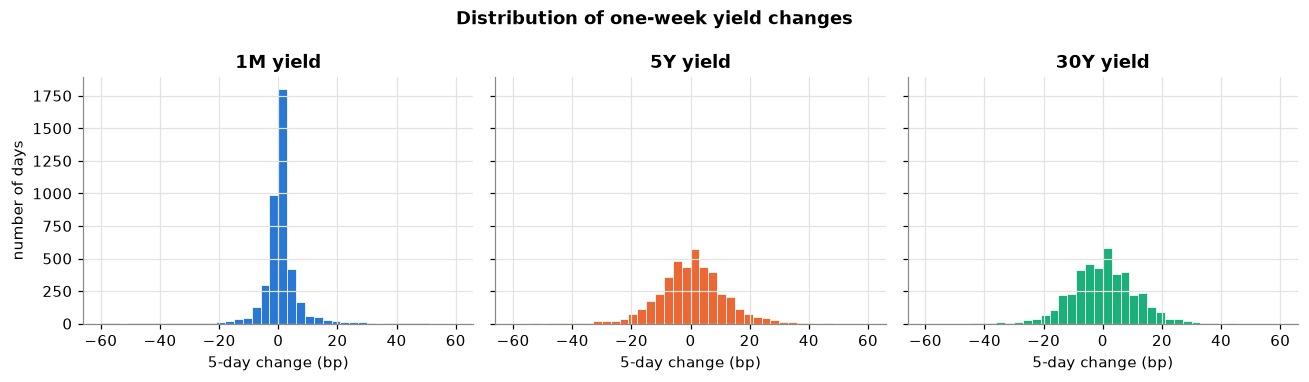

In [10]:
weekly_change = pd.DataFrame({config.TARGET_NAMES[t]: df[t].shift(-config.HORIZON) - df[t]
                              for t in config.TARGETS}).dropna()
stats = pd.DataFrame({"std (bp)": weekly_change.std() * 100,
                      "mean abs (bp)": weekly_change.abs().mean() * 100,
                      "share of weeks with no change": (weekly_change == 0).mean(),
                      "skew": weekly_change.skew(),
                      "kurtosis": weekly_change.kurt()})
print(stats.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, t in zip(axes, config.TARGETS):
    name = config.TARGET_NAMES[t]
    ax.hist(weekly_change[name] * 100, bins=np.arange(-60, 61, 3), color=plots.TARGET_COLORS[t],
            edgecolor="white", linewidth=0.5)
    ax.set_title(f"{name} yield")
    ax.set_xlabel("5-day change (bp)")
axes[0].set_ylabel("number of days")
fig.suptitle("Distribution of one-week yield changes", fontweight="bold")
plt.tight_layout()
plots.save(fig, "02_change_distribution")
plt.show()

**Observations**
- A typical one-week move is about 9-12 basis points (standard deviation).
- The 1M yield is unusual:
  - In **19%** of weeks it didn't move at all (stuck at zero in 2010-2015 and 2020-2021).
  - It also has huge jumps (kurtosis 57, where a normal distribution has 0). Its moves come in steps when the Fed changes rates, which makes it the hardest target.
- The 5Y and 30Y changes look much closer to a bell curve, with fatter tails than normal.

## 9. Level or change? (the key modelling decision)

### 9.1 Autocorrelation and stationarity

Autocorrelation shows how much today's value is related to the value some days earlier. The **ADF test** checks whether a series is stationary, i.e. has a stable mean and variance. If p < 0.05 the series is stationary.

In [11]:
rows = []
for t in config.TARGETS:
    level = df[t]
    change = (df[t].shift(-config.HORIZON) - df[t]).dropna()
    rows.append({"target": config.TARGET_NAMES[t],
                 "ADF p-value (level)": adfuller(level)[1],
                 "ADF p-value (5-day change)": adfuller(change)[1],
                 "autocorr lag 5 (level)": level.autocorr(5),
                 "autocorr lag 5 (change)": change.autocorr(5)})
pd.DataFrame(rows).set_index("target").round(4)

,ADF p-value (level),ADF p-value (5-day change),autocorr lag 5 (level),autocorr lag 5 (change)
target,,,,
1M,0.8834,0.0,0.9989,0.2616
5Y,0.9297,0.0,0.9957,-0.0139
30Y,0.7621,0.0,0.9935,-0.0790


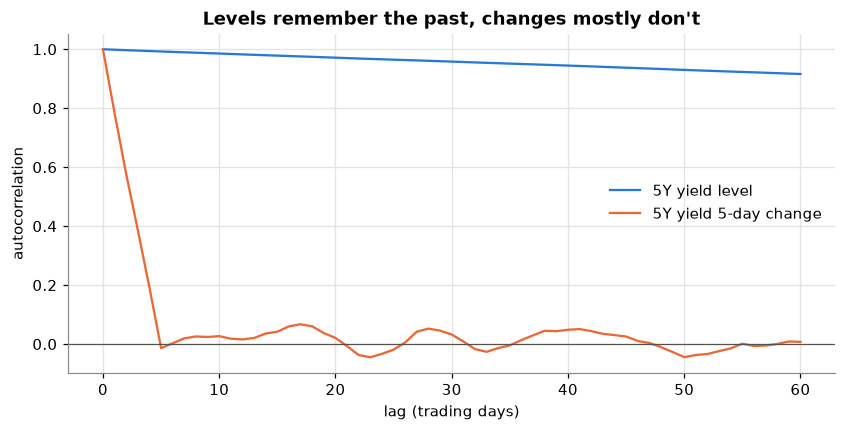

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
lags = np.arange(61)
ax.plot(lags, acf(df["DGS5"], nlags=60), color=plots.BLUE, label="5Y yield level")
change5 = (df["DGS5"].shift(-config.HORIZON) - df["DGS5"]).dropna()
ax.plot(lags, acf(change5, nlags=60), color=plots.ORANGE, label="5Y yield 5-day change")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("lag (trading days)")
ax.set_ylabel("autocorrelation")
ax.set_title("Levels remember the past, changes mostly don't")
ax.legend()
plots.save(fig, "02_autocorrelation")
plt.show()

### 9.2 The train / validation / test split

The split is by date (train 2010-2021, validation 2022, test Jan 2023 - Sep 2026). The table compares the range of each target in training with the range in the test period.

In [13]:
train = df.loc[:config.TRAIN_END]
test = df.loc[pd.Timestamp(config.VAL_END) + pd.Timedelta(days=1):]
ranges = pd.DataFrame({
    "train min": train[config.TARGETS].min(), "train max": train[config.TARGETS].max(),
    "test min": test[config.TARGETS].min(), "test max": test[config.TARGETS].max(),
    "% of test days above train max": (test[config.TARGETS] > train[config.TARGETS].max()).mean() * 100,
}).rename(index=config.TARGET_NAMES)
ranges.round(2)

,train min,train max,test min,test max,% of test days above train max
1M,0.00,2.51,3.36,6.02,100.00
5Y,0.19,3.09,3.29,5.09,100.00
30Y,0.99,4.85,3.54,5.64,25.72


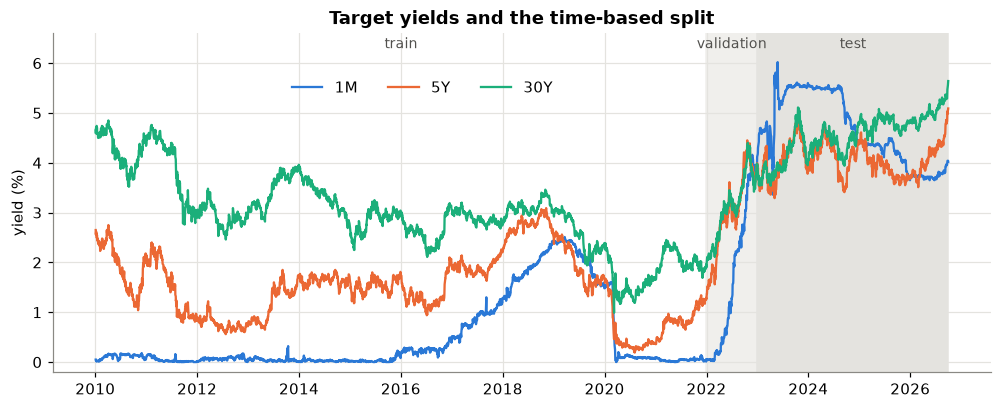

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
for t in config.TARGETS:
    ax.plot(df.index, df[t], color=plots.TARGET_COLORS[t], label=config.TARGET_NAMES[t])
split_bands = [(df.index[0], pd.Timestamp(config.TRAIN_END), "train"),
               (pd.Timestamp(config.TRAIN_END), pd.Timestamp(config.VAL_END), "validation"),
               (pd.Timestamp(config.VAL_END), df.index[-1], "test")]
for (start, end, label), shade in zip(split_bands, ["#ffffff", "#f0efec", "#e4e3df"]):
    ax.axvspan(start, end, color=shade, zorder=0)
    ax.text(start + (end - start) / 2, 6.3, label, ha="center", fontsize=9, color="#52514e")
ax.set_ylim(-0.2, 6.6)
ax.set_ylabel("yield (%)")
ax.set_title("Target yields and the time-based split")
ax.legend(loc="upper left", bbox_to_anchor=(0.24, 0.9), ncol=3)
plots.save(fig, "02_split")
plt.show()

**Observations: why we also predict the change**
- **Yield levels are not stationary** (ADF p-values 0.76 to 0.93) and their lag-5 autocorrelation is above 0.99. The value next week is almost the value today. A model that simply copies today's yield will score an R² close to 1 on levels, so a high R² on levels does **not** mean the model is good. Every model has to be compared with this "naive" forecast.
- **Weekly changes are stationary** (p ≈ 0) and barely autocorrelated, except the 1M at 0.26.
- **Every single test day** for the 1M and 5Y yields is above the highest value seen in training, and the 30Y is above it on 26% of test days.
- Tree models such as XGBoost predict by averaging training targets, so they **cannot predict a value above the training maximum**. Trained on levels, they are expected to fail on the test period.
- Weekly changes stay in roughly the same range in every period, so this problem disappears.

**Decision:** every model is trained in three experiments.
- **A, "level"** (same as the original case study): predict the yield 5 days ahead, using all 23 features.
- **B, "change"**: predict the 5-day change, then add it to today's yield. All 23 features.
- **C, "change, no yield levels"**: same target as B, but without the 8 raw yield levels as inputs. The input yield levels are just as non-stationary as the target, so a model can learn rules like "when the 5Y is around 1.5% it tends to rise" that don't apply in 2023-2026. C keeps only inputs that don't trend: spreads, recent changes, debt ratios and market indicators (15 features).

Both are scored on the rebuilt yield level, so they can be compared directly.

## 10. Which features are related to next week's change?

Correlation between each feature and the 5-day ahead change of each target, using training data only.

In [15]:
train_part = df.loc[:config.TRAIN_END]
future_change = pd.DataFrame({config.TARGET_NAMES[t]: train_part[t].shift(-config.HORIZON) - train_part[t]
                              for t in config.TARGETS})
feature_corr = pd.DataFrame({name: train_part[features.ALL_FEATURES].corrwith(future_change[name])
                             for name in future_change.columns})
feature_corr.round(3).sort_values("5Y", key=abs, ascending=False)

,1M,5Y,30Y
DGS7,0.135,-0.091,-0.095
DGS5,0.127,-0.089,-0.084
DGS10,0.133,-0.083,-0.094
GOV_PCT,0.033,0.079,0.035
DGS2,0.076,-0.062,-0.043
DGS30,0.110,-0.062,-0.087
DGS30_CHG5,0.062,-0.062,-0.129
DGS1MO,-0.036,-0.059,-0.038
HOM_PCT,-0.035,0.056,0.032
DGS3MO,-0.002,-0.052,-0.034


**Observations**
- Every correlation with next week's change is weak. The largest is 0.28.
- The strongest relationships are for the 1M yield:
  - its own change over the last 5 days (0.28, momentum: Fed moves come in a series of steps)
  - VIX (-0.19: in stressful times the short end tends to fall as investors buy safe bills and expect cuts)
  - Brent and S&P 500 returns (about +0.15)
- For the 5Y and 30Y nothing is above 0.13 in absolute value. Week-ahead moves of long yields are very hard to predict, because markets already price in most of the public information.
- **Expectation:** the models will probably beat the naive forecast only by a small margin, if at all.

## Summary of the EDA

1. The data covers very different regimes: zero rates, hikes, COVID, the fastest hikes in decades, an inverted curve and rate cuts.
2. Three factors (level, slope, curvature) explain 93% of daily curve movements.
3. Yield levels are non-stationary, and the test period has yields above anything in the training period. Tree models trained on levels can't extrapolate, so we also predict the **change** (experiment B), and in experiment C we also remove the raw yield levels from the inputs.
4. Next week's change is only weakly related to any feature, so the **naive "no change" forecast** is the benchmark every model has to beat.
5. Features: the 12 from the case study, plus 6 curve-shape and momentum features, plus 5 market features from Yahoo Finance, for 23 in total.